# Does the quantum part actually do something?  (mini pilot)

This notebook trains **3 versions of the Project Z painter** on small 32×32 dog images (CIFAR-10) and compares them.
Everything is identical except the quantum circuit:

| Version | What changes | Question it answers |
|---|---|---|
| `quantum` | nothing (normal Project Z model, 7 qubits) | the baseline |
| `no_entanglement` | the gates that connect qubits are removed → every qubit works alone | does qubits *interacting* matter? |
| `classical_twin` | the circuit is replaced by a tiny normal neural network of similar size | can normal math do the circuit's job? |
| `superposition` | **new idea:** 3×3 neighbourhood. Centre always loaded; the 8 neighbours are put in superposition with 3 *address* qubits (5 content + 3 address = 8 qubits). Branches mix inside the circuit (interference) | can quantum "attention" over neighbours work? |
| `superposition_no_interference` | same 8 branches and same circuit, but the branches never interfere; at the end a small *classical* attention weights their 8 colours | does the **interference** matter? (the key control for `superposition`) |

**Fair comparisons:** `quantum` vs `no_entanglement` vs `classical_twin` (same 5 spots), and `superposition` vs `superposition_no_interference` (same 9 spots).
Comparing `superposition` with `quantum` mixes two changes (more neighbours *and* a new circuit), so read it as a bonus, not a clean test.

**How to use**
1. In Colab: `Runtime → Change runtime type → T4 GPU`.
2. Run all cells with `QUICK_TEST = True` first (~2–5 minutes). This only checks that everything works; its numbers mean nothing.
3. Set `QUICK_TEST = False` and run everything again (roughly 2–4 hours on a free T4 for all 5 models; delete names from `MODELS` to run fewer).

**Honesty note:** this is a *pilot*, not the paper experiment. It uses 1,024 training images and 10,000 steps instead of the repo's 4,744 images and 50,000 steps,
and it is a simplified copy of `experiments/qvf_project_z/hires_models.py` (`spatial_reference`, 32px settings). Use it to learn and to get a first signal.

## 1. Settings

In [10]:
QUICK_TEST = False          # True = fast check that the code runs. False = the real pilot.

MODELS = ['quantum', 'no_entanglement', 'classical_twin', 'superposition', 'superposition_no_interference']
SEEDS        = [1]     # each model trained 3 times
N_TRAIN      = 64  if QUICK_TEST else 1024          # training dog images
STEPS        = 200 if QUICK_TEST else 10_000        # training updates
N_TEST       = 8   if QUICK_TEST else 32            # NEW dog images for the completion test
FIT_STEPS    = 100 if QUICK_TEST else 1_000         # steps to fit notes for a new image
BATCH_IMAGES = 16                                   # images per update (repo: 16)
PAIRS        = 32                                   # 32 horizontal + 32 vertical pixel pairs = 128 pixels per image per update (repo: 128)
LR           = 1e-3                                 # repo: model_lr = code_lr = 0.001
CODE_PENALTY = 1e-4                                 # repo: code_norm_weight for 32px
EDGE_WEIGHT  = 0.5                                  # repo: edge_weight
TWIN_WIDTH   = 8                                    # hidden width of the classical twin

import math, time, json
import numpy as np
import torch
from torch import nn
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)
if device == 'cpu':
    print('WARNING: no GPU. In Colab use Runtime -> Change runtime type -> T4 GPU')

device: cuda | torch 2.14.1+cu130


## 2. Data: dog photos from CIFAR-10
Training images come from the CIFAR-10 *training* set; the completion test uses dogs from the *test* set, which the model never sees during training.
Colours are scaled to 0–1. Each image is stored as 1,024 pixels × 3 colours.

In [11]:
import torchvision
train_set = torchvision.datasets.CIFAR10('data', train=True,  download=True)
test_set  = torchvision.datasets.CIFAR10('data', train=False, download=True)
DOG = 5

def dog_images(dataset, n):
    idx = [i for i, label in enumerate(dataset.targets) if label == DOG][:n]
    x = torch.tensor(dataset.data[idx], dtype=torch.float32) / 255.      # (n, 32, 32, 3)
    return x.reshape(n, 32 * 32, 3).to(device)

train_imgs = dog_images(train_set, N_TRAIN)
test_imgs  = dog_images(test_set,  N_TEST)

g = torch.linspace(0, 1, 32)
yy, xx = torch.meshgrid(g, g, indexing='ij')
COORDS = torch.stack((yy, xx), -1).reshape(-1, 2).to(device)            # (1024, 2): (row, col) in [0, 1]
print('train', tuple(train_imgs.shape), '| test', tuple(test_imgs.shape))

train (1024, 1024, 3) | test (32, 1024, 3)


## 3. A tiny quantum simulator
A state of *n* qubits is 2ⁿ numbers. We keep it as a tensor of shape `(batch, 2, 2, …, 2)` so each qubit is one axis.
`ry` rotates one qubit, `cry` rotates a qubit only when another qubit is 1 (this is what connects/entangles qubits).
Same maths as `qvf_fast.py` in the repo.

In [12]:
def ry(state, theta, wire):
    # Rotate one qubit. theta: a single number (tensor) or one angle per batch row.
    axis = wire + 1
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    if theta.dim() == 1:
        shape = (-1,) + (1,) * (state.dim() - 2)
        c, s = c.view(shape), s.view(shape)
    a0, a1 = state.unbind(axis)
    return torch.stack((c * a0 - s * a1, s * a0 + c * a1), axis)

def cry(state, theta, control, target):
    # Rotate `target` only where `control` is 1  ->  qubits interact.
    s0, s1 = state.unbind(control + 1)
    t = target if target < control else target - 1
    return torch.stack((s0, ry(s1, theta, t)), control + 1)

def positional_encoding(coords, freqs=6):
    bands = 2. ** torch.arange(freqs, device=coords.device, dtype=coords.dtype)
    x = coords[..., None] * bands
    return torch.cat((coords, torch.sin(x).flatten(-2), torch.cos(x).flatten(-2)), -1)   # 2 + 4*freqs

def read_grid(grid, coords):
    # Read a notes grid at any (row, col), blending the 4 nearest squares (bilinear).  grid: (B, 4, H, W) -> (B, Q, 4)
    B, C, H, W = grid.shape
    y = coords[:, 0].clamp(0, 1) * (H - 1); x = coords[:, 1].clamp(0, 1) * (W - 1)
    y0, x0 = y.floor().long(), x.floor().long()
    y1, x1 = (y0 + 1).clamp(max=H - 1), (x0 + 1).clamp(max=W - 1)
    dy, dx = y - y0, x - x0
    flat = grid.flatten(2)
    out = 0
    for yy_, xx_, w in ((y0, x0, (1 - dy) * (1 - dx)), (y0, x1, (1 - dy) * dx),
                        (y1, x0, dy * (1 - dx)),       (y1, x1, dy * dx)):
        out = out + flat[:, :, yy_ * W + xx_] * w
    return out.transpose(1, 2)

# quick self-check: a 1-qubit RY(pi) turns |0> into |1>
st = torch.tensor([[1., 0.]])
print('self-check (should be ~[0, 1]):', ry(st, torch.tensor(math.pi), 0).tolist())

self-check (should be ~[0, 1]): [[-4.371138828673793e-08, 1.0]]


## 4. The painter, in 3 versions
**Shared by all 3 versions (the classical front end):** each image has 336 learned numbers = notes grids of 2×2, 4×4 and 8×8 squares with 4 numbers each.
For a pixel we read the notes at 5 spots (left, above, centre, below, right), and a small network turns each spot into 5 rotation angles (one per round).

**What differs:**
* `quantum`: 7 qubits (5 spots + 2 work qubits). 5 rounds: upload each spot's angle into its qubit, then the centre qubit is connected to every other qubit (CRY gates), then a rotation on every qubit. Measure → RED = q0+q3, GREEN = q1+q4, BLUE = q2.
* `no_entanglement`: exactly the same but **without the CRY gates**. Qubits never interact.
* `classical_twin`: no circuit. The same 25 angles go (as cos/sin) into a tiny normal network that outputs RGB.

In [13]:
OFFSETS = torch.tensor([[0., -1.], [-1., 0.], [0., 0.], [1., 0.], [0., 1.]])   # left, above, centre, below, right

def mlp(inp, hidden, out, layers=3):
    dims = [inp] + [hidden] * layers
    mods = []
    for a, b in zip(dims[:-1], dims[1:]):
        mods += [nn.Linear(a, b), nn.ReLU()]
    return nn.Sequential(*mods, nn.Linear(hidden, out))

class Painter(nn.Module):
    def __init__(self, mode, grid_sizes=(2, 4, 8), freqs=6, width=128, qubits=7, rounds=5):
        super().__init__()
        assert mode in ('quantum', 'no_entanglement', 'classical_twin')
        self.mode, self.grid_sizes, self.freqs, self.n, self.rounds = mode, grid_sizes, freqs, qubits, rounds
        self.code_size = 4 * sum(s * s for s in grid_sizes)                       # 336
        self.values = nn.ModuleList(nn.Linear(4, 4) for _ in grid_sizes)
        self.encoder = mlp(12 + 2 + 4 * freqs + 2, width, rounds)                 # 40 inputs -> 5 angles
        nn.init.normal_(self.encoder[-1].weight, std=0.01); nn.init.zeros_(self.encoder[-1].bias)
        self.register_buffer('offsets', OFFSETS.clone())
        if mode == 'classical_twin':
            self.head = mlp(2 * 5 * rounds, TWIN_WIDTH, 3, layers=2)
        else:
            self.pairs = [(2, i) for i in range(qubits) if i != 2]                # star: centre <-> everyone
            self.filters = nn.Parameter(0.1 * torch.randn(rounds, 4))
            self.weights = nn.Parameter(0.1 * torch.randn(qubits, rounds))
            k = torch.arange(2 ** qubits)[:, None]
            bits = (k >> torch.arange(qubits - 1, -1, -1)) & 1
            self.register_buffer('signs', 1. - 2. * bits.float())                # for measuring Z

    # ---------- classical front end (shared) ----------
    def angles(self, codes, coords):
        B, Q = len(codes), len(coords)
        feats, start = [], 0
        for k, size in enumerate(self.grid_sizes):
            grid = codes[:, start:start + 4 * size * size].reshape(B, 4, size, size)
            start += 4 * size * size
            spots = coords[:, None] + self.offsets[None] / (size - 1)          # 5 spots, 1 square apart
            notes = read_grid(grid, spots.reshape(-1, 2)).reshape(B, Q, 5, 4)
            feats.append(self.values[k](notes))
        feats = torch.cat(feats, -1)                                             # (B, Q, 5, 12)
        pos = positional_encoding(coords, self.freqs)[None, :, None].expand(B, -1, 5, -1)
        role = self.offsets[None, None].expand(B, Q, -1, -1)
        a = math.pi * torch.tanh(self.encoder(torch.cat((feats, pos, role), -1)))  # (B, Q, 5 spots, 5 rounds)
        return a.reshape(B * Q, 5, self.rounds).transpose(1, 2)                  # (N, round, wire)

    # ---------- quantum circuit ----------
    def block(self, r):
        # The fixed (non-data) gates of round r as a 128x128 matrix:  new_state = state @ M
        d = 2 ** self.n
        st = torch.eye(d, device=self.filters.device).reshape(d, *[2] * self.n)
        f = self.filters[r]
        for a, b in self.pairs:
            st = ry(st, f[0], a); st = ry(st, f[1], b)
            if self.mode == 'quantum':                                           # <- the ONLY difference
                st = cry(st, f[2], a, b); st = cry(st, f[3], b, a)
        for q in range(self.n):
            st = ry(st, self.weights[q, r], q)
        return st.reshape(d, d)

    def forward(self, codes, coords):
        B, Q = len(codes), len(coords)
        a = self.angles(codes, coords)
        if self.mode == 'classical_twin':
            x = torch.cat((torch.cos(a), torch.sin(a)), -1).flatten(1)          # (N, 50)
            return self.head(x).reshape(B, Q, 3)
        N = len(a)
        state = torch.zeros(N, 2 ** self.n, device=a.device); state[:, 0] = 1.
        state = state.reshape(N, *[2] * self.n)
        half_pi = torch.tensor(math.pi / 2, device=a.device)
        for w in range(5):
            state = ry(state, half_pi, w)                                        # 5 data qubits start in superposition
        for r in range(self.rounds):
            for w in range(5):
                state = ry(state, a[:, r, w], w)                                 # upload spot w into qubit w
            state = (state.reshape(N, -1) @ self.block(r)).reshape(N, *[2] * self.n)
        z = state.reshape(N, -1).square() @ self.signs                           # measure every qubit: (N, 7)
        rgb = torch.stack((z[:, 0] + z[:, 3], z[:, 1] + z[:, 4], z[:, 2]), -1)
        return rgb.reshape(B, Q, 3)

## 4b. The new idea: neighbours in superposition (8 qubits)
**Content qubits (5):** hold the information of a spot. **Address qubits (3):** a label saying *which* neighbour (3 qubits = 8 labels = the 8 neighbours).

```
 [0] [1] [2]
 [3] [C] [4]      C = centre (always loaded into every branch)
 [5] [6] [7]      0–7 = neighbours, one per address label
```
Each round: (1) load the centre's angles into the content qubits; (2) **if address = k, load neighbour k's angles** (all 8 at once, because the address is in superposition);
(3) the usual processing gates on the content qubits; (4) `superposition` only: small learned rotations on the address qubits, **controlled by content qubits**, move weight between branches
→ content-dependent "attention" with interference. At the end we measure only the content qubits (address ignored) → RGB with the same rule as before.

`superposition_no_interference` runs the same 8 branches but never mixes them; a tiny classical softmax (14 weights) combines their 8 colours instead.
The circuit maths in this cell was checked against an explicit 256×256-matrix simulation (max difference ~1e-16).

In [14]:
NEIGHBOURS = torch.tensor([[-1., -1.], [-1., 0.], [-1., 1.], [0., -1.], [0., 1.], [1., -1.], [1., 0.], [1., 1.]])
OFFSETS9 = torch.cat((torch.zeros(1, 2), NEIGHBOURS))       # centre first, then neighbours 0..7
CTRL = (0, 2, 4)                                             # content wire that controls address qubit 0, 1, 2

def ry_branch(state, theta, wire):
    # state (N, 8 branches, 2,2,2,2,2): rotate content `wire` by a DIFFERENT angle in each branch. theta: (N, 8)
    axis = 2 + wire
    c, s = torch.cos(theta / 2), torch.sin(theta / 2)
    shape = tuple(theta.shape) + (1,) * (state.dim() - 3)
    c, s = c.view(shape), s.view(shape)
    a0, a1 = state.unbind(axis)
    return torch.stack((c * a0 - s * a1, s * a0 + c * a1), axis)

class SuperPainter(nn.Module):
    def __init__(self, mode, grid_sizes=(2, 4, 8), freqs=6, width=128, rounds=5):
        super().__init__()
        assert mode in ('superposition', 'superposition_no_interference')
        self.mode, self.grid_sizes, self.freqs, self.rounds = mode, grid_sizes, freqs, rounds
        self.code_size = 4 * sum(s * s for s in grid_sizes)                       # same 336 notes
        self.values = nn.ModuleList(nn.Linear(4, 4) for _ in grid_sizes)
        self.encoder = mlp(12 + 2 + 4 * freqs + 2, width, rounds * 5)             # each spot -> 5 rounds x 5 content wires
        nn.init.normal_(self.encoder[-1].weight, std=0.01); nn.init.zeros_(self.encoder[-1].bias)
        self.register_buffer('offsets', OFFSETS9.clone())
        self.pairs = [(2, i) for i in range(5) if i != 2]
        self.filters = nn.Parameter(0.1 * torch.randn(rounds, 4))
        self.weights = nn.Parameter(0.1 * torch.randn(5, rounds))
        k = torch.arange(32)[:, None]
        self.register_buffer('signs', 1. - 2. * ((k >> torch.arange(4, -1, -1)) & 1).float())
        if mode == 'superposition':
            self.alpha = nn.Parameter(0.1 * torch.randn(rounds - 1, 3))           # address rotations
            self.beta = nn.Parameter(0.1 * torch.randn(rounds - 1, 3))            # content-controlled address rotations
        else:
            self.attn = nn.Linear(5, 1)                                           # classical attention over 8 branches
            self.branch_bias = nn.Parameter(torch.zeros(8))

    def angles(self, codes, coords):
        B, Q = len(codes), len(coords)
        feats, start = [], 0
        for k, size in enumerate(self.grid_sizes):
            grid = codes[:, start:start + 4 * size * size].reshape(B, 4, size, size)
            start += 4 * size * size
            spots = coords[:, None] + self.offsets[None] / (size - 1)
            notes = read_grid(grid, spots.reshape(-1, 2)).reshape(B, Q, 9, 4)
            feats.append(self.values[k](notes))
        feats = torch.cat(feats, -1)
        pos = positional_encoding(coords, self.freqs)[None, :, None].expand(B, -1, 9, -1)
        role = self.offsets[None, None].expand(B, Q, -1, -1)
        a = math.pi * torch.tanh(self.encoder(torch.cat((feats, pos, role), -1)))   # (B, Q, 9, 25)
        return a.reshape(B * Q, 9, self.rounds, 5)                                  # (N, spot, round, wire)

    def block(self, r):
        st = torch.eye(32, device=self.filters.device).reshape(32, *[2] * 5)
        f = self.filters[r]
        for a, b in self.pairs:
            st = ry(st, f[0], a); st = ry(st, f[1], b)
            st = cry(st, f[2], a, b); st = cry(st, f[3], b, a)
        for q in range(5):
            st = ry(st, self.weights[q, r], q)
        return st.reshape(32, 32)

    def forward(self, codes, coords):
        B, Q = len(codes), len(coords)
        a = self.angles(codes, coords)
        N = len(a)
        centre, nbr = a[:, 0], a[:, 1:]                                             # (N,5,5), (N,8,5,5)
        start = 1 / 16. if self.mode == 'superposition' else 1 / math.sqrt(32)      # equal superposition
        state = torch.full((N, 8, 32), start, device=a.device).reshape(N, 8, *[2] * 5)
        for r in range(self.rounds):
            for w in range(5):
                state = ry(state, centre[:, r, w], 1 + w)                          # centre: same in every branch
                state = ry_branch(state, nbr[:, :, r, w], w)                        # neighbour k in branch k
            state = (state.reshape(N * 8, 32) @ self.block(r)).reshape(N, 8, *[2] * 5)
            if self.mode == 'superposition' and r < self.rounds - 1:
                full = state.reshape(N, *[2] * 8)                                   # wires 0-2 address, 3-7 content
                for j in range(3):
                    full = ry(full, self.alpha[r, j], j)
                    full = cry(full, self.beta[r, j], 3 + CTRL[j], j)
                state = full.reshape(N, 8, *[2] * 5)
        probs = state.reshape(N, 8, 32).square()
        if self.mode == 'superposition':
            z = probs.sum(1) @ self.signs                                           # ignore address, measure content
            rgb = torch.stack((z[:, 0] + z[:, 3], z[:, 1] + z[:, 4], z[:, 2]), -1)
        else:
            z = probs @ self.signs                                                  # (N, 8, 5): one result per branch
            rgb_k = torch.stack((z[..., 0] + z[..., 3], z[..., 1] + z[..., 4], z[..., 2]), -1)
            w8 = torch.softmax(self.attn(z).squeeze(-1) + self.branch_bias, -1)
            rgb = (w8[..., None] * rgb_k).sum(1)
        return rgb.reshape(B, Q, 3)

def make_model(mode):
    return SuperPainter(mode) if mode.startswith('superposition') else Painter(mode)

DIFF = ('filters', 'weights', 'alpha', 'beta', 'branch_bias')
for m in MODELS:
    p = make_model(m)
    total = sum(x.numel() for x in p.parameters())
    part = sum(x.numel() for n_, x in p.named_parameters() if n_ in DIFF or n_.startswith(('head', 'attn')))
    qubits = {'quantum': 7, 'no_entanglement': 7, 'classical_twin': 0}.get(m, 8)
    print(f'{m:30s} qubits: {qubits}  total shared weights: {total:,}  | circuit/head part: {part}')

quantum                        qubits: 7  total shared weights: 39,032  | circuit/head part: 55
no_entanglement                qubits: 7  total shared weights: 39,032  | circuit/head part: 55
classical_twin                 qubits: 0  total shared weights: 39,484  | circuit/head part: 507
superposition                  qubits: 8  total shared weights: 41,626  | circuit/head part: 69
superposition_no_interference  qubits: 8  total shared weights: 41,616  | circuit/head part: 59


## 5. Training and the completion test
**Training:** the painter's weights and every training image's notes are learned together (like the repo). Each update uses 16 images × 128 pixels
(as neighbouring pairs, so we can also penalise blurry edges: loss = pixel error + 0.5 × edge error + small notes penalty).

**Completion test (the main score):** freeze the painter, take NEW dog images, show it only 256 of the 1,024 pixels, fit fresh notes for 1,000 steps,
then score the 768 **hidden** pixels. PSNR (higher = better) and edge error (lower = better).

In [15]:
def sample_pairs(n):
    # n horizontal + n vertical neighbouring pixel pairs, flattened so each consecutive 2 entries are a pair
    r = torch.randint(0, 32, (n,)); c = torch.randint(0, 31, (n,))
    h = torch.stack((r * 32 + c, r * 32 + c + 1), 1)
    r2 = torch.randint(0, 31, (n,)); c2 = torch.randint(0, 32, (n,))
    v = torch.stack((r2 * 32 + c2, (r2 + 1) * 32 + c2), 1)
    return torch.cat((h, v)).flatten().to(device)

def objective(pred, target, codes):
    err = pred - target
    pixel = err.square().mean()
    pairs = err.reshape(len(err), -1, 2, 3)
    edge = (pairs[:, :, 1] - pairs[:, :, 0]).square().mean()
    return pixel + EDGE_WEIGHT * edge + CODE_PENALTY * codes.norm(dim=1).mean()

@torch.no_grad()
def render(model, codes, chunk=256):
    return torch.cat([model(codes, COORDS[i:i + chunk]) for i in range(0, 1024, chunk)], 1)

def psnr_per_image(pred, target):
    mse = (pred - target).square().mean((1, 2)).clamp_min(1e-10)
    return (10 * torch.log10(1 / mse)).mean().item()

def edge_error(pred, target, mask=None):
    # finite-difference error over horizontal + vertical neighbours; if mask given, only pairs with BOTH pixels in mask
    e = (pred - target).reshape(-1, 32, 32, 3)
    dh = e[:, :, 1:] - e[:, :, :-1]; dv = e[:, 1:] - e[:, :-1]
    if mask is None:
        return torch.cat((dh.square().flatten(), dv.square().flatten())).mean().item()
    m = mask.reshape(32, 32)
    mh = (m[:, 1:] & m[:, :-1]); mv = (m[1:] & m[:-1])
    return torch.cat((dh[:, mh].square().flatten(), dv[:, mv].square().flatten())).mean().item()

def train(mode, seed):
    torch.manual_seed(seed)
    model = make_model(mode).to(device)
    codes = nn.Parameter(0.01 * torch.randn(N_TRAIN, model.code_size, device=device))
    opt = torch.optim.Adam([{'params': model.parameters()}, {'params': [codes]}], lr=LR)
    t0 = time.time()
    for step in range(1, STEPS + 1):
        idx = torch.randint(0, N_TRAIN, (BATCH_IMAGES,), device=device)
        q = sample_pairs(PAIRS)
        loss = objective(model(codes[idx], COORDS[q]), train_imgs[idx][:, q], codes[idx])
        opt.zero_grad(); loss.backward(); opt.step()
        if step % max(1, STEPS // 10) == 0:
            print(f'   {mode} seed{seed} step {step:>6}/{STEPS}  loss {loss.item():.5f}  ({time.time() - t0:.0f}s)')
    probe = min(64, N_TRAIN)
    pred = render(model, codes[:probe].detach())
    return model, {'train_psnr': psnr_per_image(pred, train_imgs[:probe]),
                   'train_edge': edge_error(pred, train_imgs[:probe]),
                   'train_seconds': time.time() - t0}

def completion(model, seed):
    for p in model.parameters():
        p.requires_grad_(False)
    g = torch.Generator().manual_seed(1234)                       # same visible pixels for every model
    perm = torch.randperm(1024, generator=g).to(device)
    seen, hidden = perm[:256], perm[256:]
    torch.manual_seed(10_000 + seed)
    codes = nn.Parameter(0.01 * torch.randn(N_TEST, model.code_size, device=device))
    opt = torch.optim.Adam([codes], lr=LR)
    for _ in range(FIT_STEPS):
        q = seen[torch.randint(0, 256, (128,), device=device)]   # 128 of the visible pixels per step
        loss = (model(codes, COORDS[q]) - test_imgs[:, q]).square().mean() + CODE_PENALTY * codes.norm(dim=1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    pred = render(model, codes.detach())
    mask = torch.zeros(1024, dtype=torch.bool, device=device); mask[hidden] = True
    return pred, seen, {'completion_psnr': psnr_per_image(pred[:, hidden], test_imgs[:, hidden]),
                        'completion_edge': edge_error(pred, test_imgs, mask)}

## 6. Run everything
Results are saved to `results.json` after every run. (Optional: mount Google Drive and change `SAVE_PATH` so results survive a disconnect.)

In [16]:
SAVE_PATH = 'results.json'
results, examples = [], {}
for seed in SEEDS:
    for mode in MODELS:
        print(f'\n=== {mode} | seed {seed} ===')
        model, row = train(mode, seed)
        pred, seen, comp = completion(model, seed)
        row.update(comp); row.update({'model': mode, 'seed': seed})
        results.append(row)
        if seed == SEEDS[0]:
            examples[mode] = pred.cpu()
        print('   ->', {k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
        json.dump({'quick_test': QUICK_TEST, 'results': results}, open(SAVE_PATH, 'w'), indent=1)
        del model; torch.cuda.empty_cache() if device == 'cuda' else None
print('\nDONE')


=== quantum | seed 1 ===
   quantum seed1 step   1000/10000  loss 0.02171  (146s)
   quantum seed1 step   2000/10000  loss 0.01273  (290s)
   quantum seed1 step   3000/10000  loss 0.00985  (433s)
   quantum seed1 step   4000/10000  loss 0.01118  (576s)
   quantum seed1 step   5000/10000  loss 0.01243  (719s)
   quantum seed1 step   6000/10000  loss 0.01008  (864s)
   quantum seed1 step   7000/10000  loss 0.01019  (1009s)
   quantum seed1 step   8000/10000  loss 0.00917  (1155s)
   quantum seed1 step   9000/10000  loss 0.00710  (1301s)
   quantum seed1 step  10000/10000  loss 0.00811  (1447s)
   -> {'train_psnr': 22.3718, 'train_edge': 0.0052, 'train_seconds': 1447.4254, 'completion_psnr': 21.0051, 'completion_edge': 0.0056, 'model': 'quantum', 'seed': 1}

=== no_entanglement | seed 1 ===
   no_entanglement seed1 step   1000/10000  loss 0.03002  (99s)
   no_entanglement seed1 step   2000/10000  loss 0.01747  (198s)
   no_entanglement seed1 step   3000/10000  loss 0.01204  (296s)
   no_

## 7. Results
* **PSNR:** higher = better picture. **Edge error:** lower = sharper.
* A difference below about **0.2 dB** is basically noise.
* "Paired difference" = (version − quantum) for the same seed, averaged. Negative PSNR difference = that version is worse than quantum.

In [17]:
import pandas as pd
df = pd.DataFrame(results)
cols = ['completion_psnr', 'completion_edge', 'train_psnr', 'train_edge', 'train_seconds']
summary = df.groupby('model')[cols].agg(['mean', 'std']).reindex(MODELS)
display(summary.round(4))

base = df[df.model == 'quantum'].set_index('seed')
for m in [x for x in MODELS if x != 'quantum' and 'quantum' in set(df.model)]:
    other = df[df.model == m].set_index('seed')
    d = (other['completion_psnr'] - base['completion_psnr']).dropna()
    print(f'{m:30s} completion PSNR minus quantum: {d.mean():+.3f} dB  (per seed: {[round(x, 3) for x in d]})')
if {'superposition', 'superposition_no_interference'} <= set(df.model):
    sp = df[df.model == 'superposition'].set_index('seed')['completion_psnr']
    ni = df[df.model == 'superposition_no_interference'].set_index('seed')['completion_psnr']
    d = (sp - ni).dropna()
    print(f'\nKEY TEST  superposition minus no_interference: {d.mean():+.3f} dB  (per seed: {[round(x, 3) for x in d]})')
    print('          positive in every seed -> interference helps; about 0 -> it does not')
if QUICK_TEST:
    print('\nQUICK_TEST: these numbers are meaningless. Set QUICK_TEST = False and run again.')

completion_psnr     completion_edge      \
                                         mean std            mean std   
model                                                                   
quantum                               21.0051 NaN          0.0056 NaN   
no_entanglement                       20.0570 NaN          0.0065 NaN   
classical_twin                        12.1947 NaN          0.0087 NaN   
superposition                         21.1551 NaN          0.0056 NaN   
superposition_no_interference         20.9467 NaN          0.0057 NaN   

                              train_psnr     train_edge     train_seconds      
                                    mean std       mean std          mean std  
model                                                                          
quantum                          22.3718 NaN     0.0052 NaN     1447.4254 NaN  
no_entanglement                  20.6638 NaN     0.0068 NaN      975.0237 NaN  
classical_twin                   12.8583 NaN     0.0096 NaN       98.3678 NaN  
superposition                    22.5621 NaN     0.0050 NaN     1410.1138 NaN  
superposition_no_interference    22.7469 NaN     0.0049 NaN     1225.2534 NaN

no_entanglement                completion PSNR minus quantum: -0.948 dB  (per seed: [-0.948])
classical_twin                 completion PSNR minus quantum: -8.810 dB  (per seed: [-8.81])
superposition                  completion PSNR minus quantum: +0.150 dB  (per seed: [0.15])
superposition_no_interference  completion PSNR minus quantum: -0.058 dB  (per seed: [-0.058])

KEY TEST  superposition minus no_interference: +0.208 dB  (per seed: [0.208])
          positive in every seed -> interference helps; about 0 -> it does not


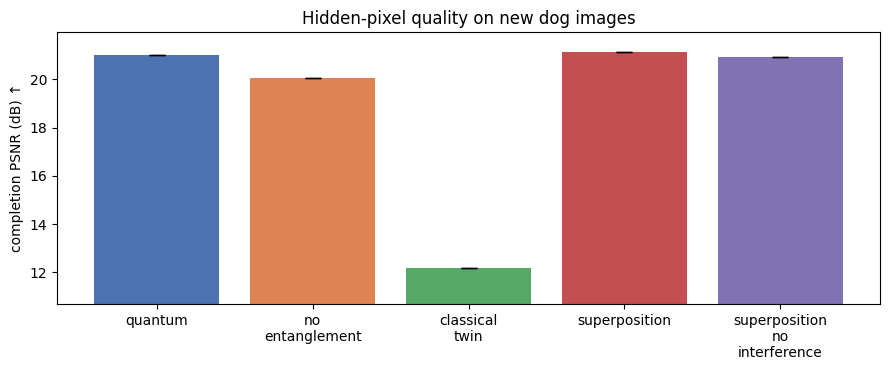

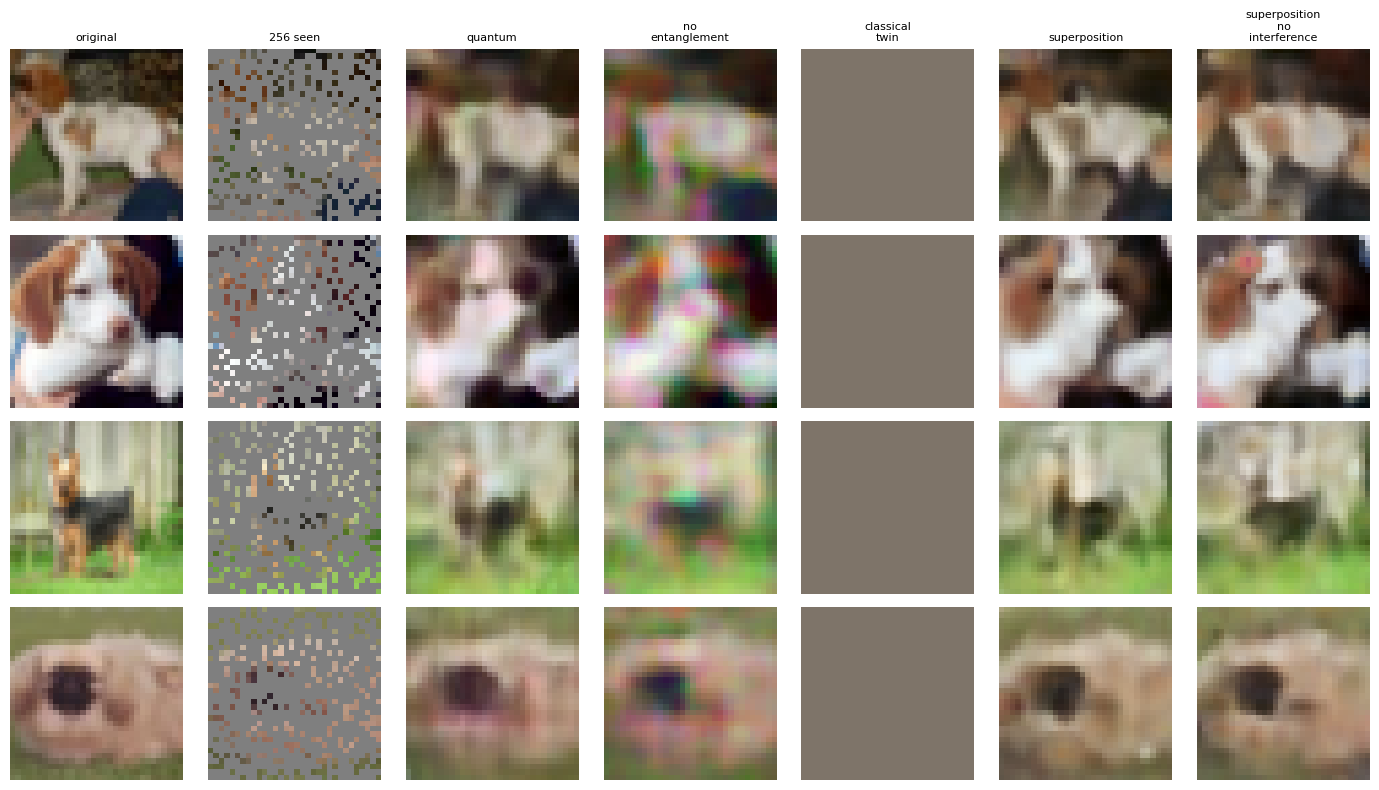

In [18]:
import matplotlib.pyplot as plt
means = df.groupby('model')['completion_psnr'].mean().reindex(MODELS)
stds = df.groupby('model')['completion_psnr'].std().reindex(MODELS).fillna(0)
plt.figure(figsize=(9, 3.8))
plt.bar([m.replace('_', '\n') for m in MODELS], means, yerr=stds, capsize=6, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3'][:len(MODELS)])
plt.ylim(means.min() - 1.5, means.max() + 0.8)
plt.ylabel('completion PSNR (dB) ↑'); plt.title('Hidden-pixel quality on new dog images')
plt.tight_layout(); plt.show()

# Example completions: original | what the model saw | each version's guess
n_show = min(4, N_TEST)
fig, ax = plt.subplots(n_show, 2 + len(MODELS), figsize=(2 * (2 + len(MODELS)), 2 * n_show))
ax = np.atleast_2d(ax)
seen_mask = torch.zeros(1024, dtype=torch.bool); seen_mask[seen.cpu()] = True
for i in range(n_show):
    orig = test_imgs[i].cpu()
    shown = orig.clone(); shown[~seen_mask] = 0.5
    panels = [('original', orig), ('256 seen', shown)] + [(m, examples[m][i]) for m in MODELS]
    for j, (title, img) in enumerate(panels):
        ax[i, j].imshow(img.reshape(32, 32, 3).clamp(0, 1).numpy()); ax[i, j].axis('off')
        if i == 0: ax[i, j].set_title(title.replace('_', '\n'), fontsize=8)
plt.tight_layout(); plt.show()

## 8. How to read the result
| What you see | What it means |
|---|---|
| `quantum` clearly better than **both** others (> ~0.3 dB, in every seed) | the circuit, and qubits interacting, help. Good sign for the paper |
| `quantum` ≈ `no_entanglement` | qubits interacting doesn't matter; the circuit acts like independent simple functions |
| `quantum` ≈ `classical_twin` (or twin better) | a tiny normal network can do the circuit's job; the gain comes from the classical parts (notes map, front end) |
| `superposition` > `superposition_no_interference` in every seed | **quantum interference between neighbours helps**: the most "quantum" result you could get |
| `superposition` ≈ `superposition_no_interference` | the superposition trick works as a design, but interference itself adds nothing |

Whatever you find, it is a **pilot**: 1,024 images, 10k steps, one dataset. If it shows something interesting, the next step is the full version inside the repo
(4,744 images, 50k steps, 32px **and** 256px), run on the server.